# 1: Getting started
## This code generates the figures for the relationship between position and price, and between position and the CPP


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('train.parquet')
RES = Path('res')
RES.mkdir(exist_ok=True)

MAX_POS = 25     # the last positions are very noisy (as in getting_started)
SPECIAL_SLOTS = [5, 11, 17, 23]   # special slots: empty in most sessions, so very few observations


### Import data

In [2]:
cols = ['srch_id', 'position', 'random_bool', 'click_bool', 'booking_bool', 'price_usd']
dat = pd.read_parquet(DATA, columns=cols)

# as in getting_started: a few listings have a price of zero, so log price fails: drop their sessions
price_min = dat.groupby('srch_id')['price_usd'].transform('min')
dat = dat[price_min > 0]

# Ursu (2018, fn. 15): positions 5, 11, 17, 23 are reserved for opaque offers, which are not in the data.
# A hotel only appears there when the session showed no opaque offers, so drop those sessions.
has_hotel_in_slot = dat['position'].isin(SPECIAL_SLOTS).groupby(dat['srch_id']).transform('any')
sess = dat.groupby('srch_id')['random_bool'].first().map({0: 'Expedia ranking', 1: 'Random ranking'})
dropped = dat.loc[has_hotel_in_slot, 'srch_id'].unique()
drop_tab = pd.DataFrame({'Sessions before': sess.value_counts(),
                         'Dropped': sess.loc[dropped].value_counts()}).fillna(0).astype(int).rename_axis('Ordering')
drop_tab['Share dropped'] = (drop_tab['Dropped'] / drop_tab['Sessions before']).round(4)
print('Sessions dropped (hotel in position 5, 11, 17 or 23):')
print(drop_tab, end='\n\n')
dat = dat[~has_hotel_in_slot]

dat['log_price'] = np.log(dat['price_usd'])
# price relative to the session's average: compares hotels within the same list
dat['log_price_rel'] = dat['log_price'] - dat.groupby('srch_id')['log_price'].transform('mean')
dat['ordering'] = dat['random_bool'].map({0: 'Expedia ranking', 1: 'Random ranking'})
dat = dat.query('position <= @MAX_POS')

print(f"Sessions: {dat['srch_id'].nunique():,}  Listings: {len(dat):,}")

Sessions dropped (hotel in position 5, 11, 17 or 23):
                 Sessions before  Dropped  Share dropped
Ordering                                                
Expedia ranking           277794    26542         0.0955
Random ranking            121545     2571         0.0212

Sessions: 370,226  Listings: 6,779,808


In [3]:
from matplotlib.lines import Line2D

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'CMU Serif', 'Times New Roman', 'DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'font.size': 10, 'axes.labelsize': 10, 'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.8,
    'xtick.major.width': 0.8, 'ytick.major.width': 0.8,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#D7D7E9', 'grid.linewidth': 0.6,
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
})

# palette: #2D004B, #8170AC, #D7D7E9, #FDDDB3, #DD841F, #7F3B08
# different markers and line styles, so the figures also read in black and white
STYLE = {'Expedia ranking': dict(color='#2D004B', marker='o', ls='-'),
         'Random ranking':  dict(color='#DD841F', marker='s', ls='--')}

def plot_by_position(df, y, ylabel, fname, hline=None):
    '''Mean of y by position for each ordering; saves pdf in RES and returns the table.
    Lines connect only the regular positions; the special slots are shown as hollow,
    unconnected markers, and the y-axis is scaled from the regular positions only.'''
    tab = df.groupby(['ordering', 'position'])[y].mean().unstack('ordering')
    special = tab.index.isin(SPECIAL_SLOTS)
    reg, spec = tab[~special], tab[special]

    fig, ax = plt.subplots(figsize=(6.0, 3.4))
    if hline is not None:
        ax.axhline(hline, color='0.4', lw=0.8, zorder=1)
    for ordering in ['Expedia ranking', 'Random ranking']:
        ax.plot(reg.index, reg[ordering], ms=4, lw=1.4, label=ordering, zorder=3, **STYLE[ordering])

    # freeze the y-axis at the range of the regular positions before adding the special slots
    ax.set_ylim(ax.get_ylim())
    for ordering in ['Expedia ranking', 'Random ranking']:
        st = STYLE[ordering]
        ax.plot(spec.index, spec[ordering], ls='none', marker=st['marker'], ms=4,
                mec=st['color'], mfc='none', mew=1.0, zorder=3)

    ax.set_xlabel('Position in list')
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(1, MAX_POS + 1, 2))
    ax.set_xlim(0.5, MAX_POS + 0.5)
    handles, labels = ax.get_legend_handles_labels()
    handles.append(Line2D([], [], ls='none', marker='o', ms=4, mec='0.5', mfc='none', mew=1.0))
    labels.append(f"Special slots ({', '.join(map(str, SPECIAL_SLOTS))})")
    ax.legend(handles, labels, frameon=False)
    fig.savefig(RES / f'{fname}.pdf')
    plt.show()
    return tab

### Figure 1.1a

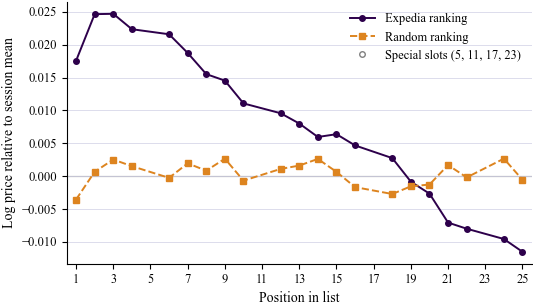

In [4]:
tab_a = plot_by_position(dat, 'log_price_rel', 'Log price relative to session mean',
                         'fig_1_1a_price_by_position', hline=0)

### Figure 1.1b

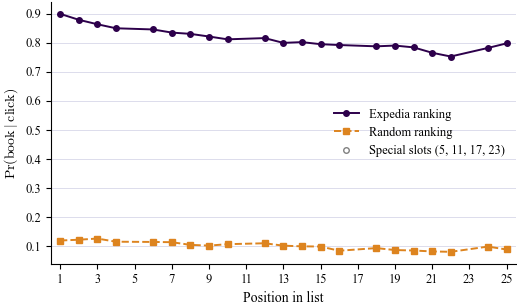

In [5]:
tab_b = plot_by_position(dat.query('click_bool == 1'), 'booking_bool',
                         r'$\Pr(\mathrm{book} \mid \mathrm{click})$', 'fig_1_1b_book_given_click')

### Save

In [6]:
sorted(p.name for p in RES.iterdir())

['.DS_Store',
 'fig_1_1a_price_by_position.pdf',
 'fig_1_1b_book_given_click.pdf']

# 2: Theoretical Part
## Exercise 2.4.iv

A simplified Zhou model:
- n=2
- u ~ U(0,1)
- Firm 1 is free to visit. Firm 2 costs s in (0, 1/8) to visit
- Consumers observe u and p upon visiting

In [7]:
import numpy as np
from scipy.optimize import fsolve
import matplotlib.pyplot as plt

s = 0.001:  p1 = 0.4187,  p2 = 0.4275
s = 0.013:  p1 = 0.4318,  p2 = 0.4541
s = 0.037:  p1 = 0.4506,  p2 = 0.4780
s = 0.062:  p1 = 0.4663,  p2 = 0.4902
s = 0.100:  p1 = 0.4872,  p2 = 0.4986
s = 0.125:  p1 = 0.5000,  p2 = 0.5000


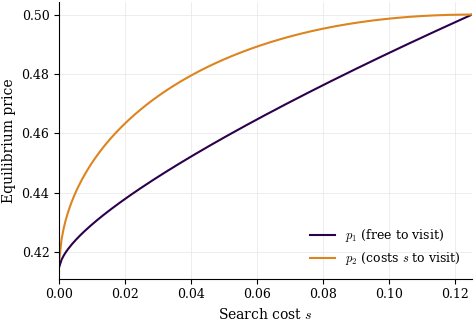

In [8]:
def profits(pt1, pt2, p2, s):
    """Profits given actual prices (pt1, pt2) and the expected price p2."""
    z = 1 - np.sqrt(2 * s) - p2                 # z_2 = a - p_2: search firm 2 iff u1 - pt1 < z
    back1 = z**2 / 2 + pt2 * z                  # search, then return to firm 1
    back2 = z**2 / 2 + pt1 * z                  # buy at firm 2 after comparing with firm 1
    return pt1 * (1 - pt1 - z + back1), pt2 * ((pt1 + z) * (1 - pt2 - z) + back2)


def focs(p, s, h=1e-6):
    """Each firm's marginal profit in its own price, at pt = p (rational expectations)."""
    p1, p2 = p
    d1 = (profits(p1 + h, p2, p2, s)[0] - profits(p1 - h, p2, p2, s)[0]) / (2 * h)
    d2 = (profits(p1, p2 + h, p2, s)[1] - profits(p1, p2 - h, p2, s)[1]) / (2 * h)
    return [d1, d2]


def solve_equilibrium(s, guess=(0.45, 0.45)):
    return fsolve(focs, guess, args=(s,))

for s in [1/8*0.01, 1/8*0.1, 1/8*0.3, 1/8*0.5, 1/8*0.8, 1/8]:
    p1, p2 = solve_equilibrium(s)
    print(f"s = {s:.3f}:  p1 = {p1:.4f},  p2 = {p2:.4f}")


plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'CMU Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'axes.unicode_minus': False,
})

STYLE = {'p1': dict(color='#2D004B', ls='-'),
         'p2': dict(color='#DD841F', ls='-')}

s_grid = np.linspace(1e-4, 1/8, 200)
eq = []
guess = (0.45, 0.45)
for s in s_grid:
    guess = solve_equilibrium(s, guess)   # warm start from previous s
    eq.append(guess)
eq = np.array(eq)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(s_grid, eq[:, 0], label=r"$p_1$ (free to visit)", **STYLE['p1'])
ax.plot(s_grid, eq[:, 1], label=r"$p_2$ (costs $s$ to visit)", **STYLE['p2'])

ax.set_xlabel(r"Search cost $s$")
ax.set_ylabel("Equilibrium price")

ax.set_xlim(0, 1/8)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(True, color="0.9", lw=0.5)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(RES / 'zhou_prices.pdf')
plt.show()

# 3: Empirical Part

1. **Baseline model**: multinomial logit on bookings, random-ranking sessions, log position. Identifies $\theta = \beta - \gamma$.
2. **Extended model**: splits $\theta$ into taste $\beta$ and search cost $\gamma$ with two-step simulated least squares on the clicks (PS9).

All results are printed in the **Results** section at the bottom.

In [41]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize, brentq
from itertools import product
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt
from ps8_tools import simulate_search

DATA = Path('train.parquet')
RES = Path('res'); RES.mkdir(exist_ok=True)

# True: estimate the baseline and run the grid (about half an hour), and save both to res/.
# False: load theta from res/estimates.csv and the grid from res/grid_Q.csv instead.
RUN_GRID = False

# Data

Long format, indexed by $(i, j)$: $i$ is the session (`srch_id`) and $j$ the listing's position in it. Each session also gets a row for the outside option, $j = 0$. $j$ is a label, not a counter.

In [42]:
# only the columns used below (all 54 columns take about 9 GB of memory at the peak)
cols = ['srch_id', 'position', 'random_bool', 'click_bool', 'booking_bool', 'price_usd',
        'prop_starrating', 'prop_review_score', 'prop_brand_bool', 'prop_location_score1', 'promotion_flag']
dat = pd.read_parquet(DATA, columns=cols)


In [43]:
frac = 0.2 # the share of sessions to keep: the full data are slow to estimate on
price_min = dat.groupby('srch_id')['price_usd'].min()
idx_i = price_min.index[price_min > 0] # a few listings have a price of zero, so log price fails: drop their sessions
idx_i = pd.Series(idx_i).sample(frac=frac, random_state=1).values
I_sample = dat['srch_id'].isin(idx_i)
df = dat[I_sample]
df = df.set_index(['srch_id', 'position']).sort_index()
df.index.names = ['i', 'j']
df = df.select_dtypes('number') # numbers only, because the outside rows will be zeros

# the regressors, built before the outside rows go in, so that those rows get zeros
df['log_price'] = np.log(df['price_usd'])
df['stars'] = df['prop_starrating'].astype(float)
df['review'] = df['prop_review_score']
df['zero_stars'] = (df['stars'] == 0).astype(float)   # 1 if the hotel has no star rating (stars = 0)
df['zero_review'] = (df['review'] == 0).astype(float) # 1 if the hotel has no reviews (review = 0); NaN reviews give 0 here
df['position_num'] = df.index.get_level_values('j').astype(float) # Rank_ij
df['position_log'] = np.log(df['position_num']) # log(Rank_ij)
df['constant'] = 1.0

# the outside option: one row per session, j = 0, with every column zero, so delta_i0 = 0
idx_outside = pd.MultiIndex.from_product([df.index.get_level_values('i').unique(), [0]], names=['i', 'j'])
df = df.reindex(df.index.append(idx_outside), fill_value=0).sort_index()

I_outside = df.index.get_level_values('j') == 0
booked_any = df.groupby(level='i')['booking_bool'].transform('max') # 1 if the session booked a hotel
booked_any = booked_any[I_outside]
df.loc[I_outside, 'click_bool'] = 1 # the outside option is always "searched", as in PS8
df.loc[I_outside, 'booking_bool'] = 1 - booked_any # and it is chosen when no hotel is booked

# give the outside row the session's random_bool (it is 0 after the reindex)
df['random_bool'] = df.groupby(level='i')['random_bool'].transform('max')

assert (df.groupby(level='i')['booking_bool'].sum() == 1).all() # exactly one choice per session

In [44]:
### Random-ranking sessions
# filter on random_bool = 1, i.e. the random ranking subsample
df_rand = df[df['random_bool'] == 1]

# drop the sessions where any hotel has a missing review, and note what is dropped
miss_review = df_rand['review'].isna().groupby(level='i').transform('any')
n_sess, n_rows = df_rand.index.get_level_values('i').nunique(), len(df_rand)
drop_sess = df_rand[miss_review].index.get_level_values('i').unique()
print(f'hotel rows with missing review: {df_rand["review"].isna().sum()}')
print(f'sessions dropped: {len(drop_sess)} of {n_sess} ({len(drop_sess)/n_sess:.1%})')
print(f'rows dropped (incl. outside rows): {miss_review.sum()} of {n_rows} ({miss_review.sum()/n_rows:.1%})')
print(f'bookings in dropped sessions: {df_rand.loc[miss_review & (df_rand.index.get_level_values("j") > 0), "booking_bool"].sum()}')
df_rand = df_rand[~miss_review]
I_chosen_rand = df_rand['booking_bool'] == 1

hotel rows with missing review: 1236
sessions dropped: 911 of 24316 (3.7%)
rows dropped (incl. outside rows): 24055 of 612801 (3.9%)
bookings in dropped sessions: 98


# Functions

`loglike` is the PS9 likelihood with $\gamma = 0$. `price_change` gives the log-price equivalent of moving from position `pos` to `pos-1`. `predict_shares` gives the logit choice probabilities. The rest are for the simulated least squares in the extended model.

In [45]:
def loglike(beta, X, I_chosen):
    '''Minus the average log-likelihood of the logit.'''
    v = X @ beta
    v -= v.groupby(level='i').transform('max') # for numerical stability
    log_probs = v - np.log(np.exp(v).groupby(level='i').transform('sum'))
    return -np.mean(log_probs[I_chosen].values)


def price_change(theta, pos, pos_var='position_log'):
    '''Change in log price that keeps the booking probability constant when moving from pos to pos-1.'''
    d_pos = (np.log(pos - 1) - np.log(pos)) if pos_var == 'position_log' else -1.0
    return -theta[pos_var] / theta['log_price'] * d_pos

def predict_shares(theta, d):
    """
    theta: pd.Series of estimates, indexed by variable name (e.g. pd.Series(res.x, xvars))
    d:     long data with index (i, j), including the outside rows (j = 0)
    returns: pd.Series of s_ij, one per row
    """
    v = d[list(theta.index)].astype(float) @ theta.values          # utility x_ij' theta (outside rows: 0)
    v = v - v.groupby(level='i').transform('max')                  # for numerical stability; shares unchanged
    ev = np.exp(v)
    return ev / ev.groupby(level='i').transform('sum')             # logit share within each session

def gamma_from(gamma_0, gamma_pos, xv=None, pos_var='position_log'):
    '''gamma over the columns of xv (default: xvars): zero except on the constant and the position variable.'''
    xv = xvars if xv is None else xv
    gamma = pd.Series(0.0, index=xv)
    gamma['constant'], gamma[pos_var] = gamma_0, gamma_pos
    return gamma

def simulated_searches(delta, mu, eps, seed):
    """a_ij^(r): one simulated search dummy for every session and inside option."""
    d_, searched_ = simulate_search(delta, mu, eps, seed=seed)
    I_inside_ = searched_.index.get_level_values('j') > 0 # the outside option is always "searched"
    searched_ = searched_[I_inside_]
    return searched_

def grid_search(X_, theta_, a_data_, eps_draws_, xv=None, pos_var='position_log', g0_grid_=None, gp_grid_=None):
    '''Q(gamma | theta_) on the grid, conditioning on >= 1 search per session. Defaults: the global xvars, g0_grid, gp_grid.'''
    g0s = g0_grid if g0_grid_ is None else g0_grid_
    gps = gp_grid if gp_grid_ is None else gp_grid_
    rows = []
    for g0, gp in tqdm(list(product(g0s, gps)), desc=f'grid {pos_var}, R = {len(eps_draws_)}'):
        gamma = gamma_from(g0, gp, xv, pos_var)
        beta = theta_ + gamma
        a_sim = pd.concat([simulated_searches(X_ @ beta, X_ @ gamma, eps, seed=3 + r)
                           for r, eps in enumerate(eps_draws_)], axis=1).astype(float)
        any_search = a_sim.groupby(level='i').transform('max')
        a_bar = (a_sim * any_search).sum(axis=1) / any_search.sum(axis=1)
        rows.append({'gamma_0': g0, 'gamma_pos': gp, 'Q': ((a_data_ - a_bar) ** 2).mean()})
    return pd.DataFrame(rows)

def sim_click_rate(theta_, X_, g0, gp, eps_draws_):
    """Simulated click rate by position at gamma = (g0, gp), conditioning on >= 1 search per session."""
    gamma = gamma_from(g0, gp)
    beta = theta_ + gamma
    a_sim = pd.concat([simulated_searches(X_ @ beta, X_ @ gamma, eps, seed=3 + r)
                       for r, eps in enumerate(eps_draws_)], axis=1).astype(float)
    any_search = a_sim.groupby(level='i').transform('max')
    a_bar = (a_sim * any_search).sum(axis=1) / any_search.sum(axis=1)
    return a_bar.groupby(level='j').mean()

# Baseline model
Random-ranking data, log position.

In [46]:
# the variables in x_ij
xvars = ['log_price', 'stars', 'zero_stars', 'position_log', 'review', 'zero_review', 'prop_brand_bool', 'prop_location_score1', 'promotion_flag', 'constant']
X_rand = df_rand[xvars].astype(float)

if RUN_GRID:
    res_baseline = minimize(loglike, np.zeros(len(xvars)), args=(X_rand, I_chosen_rand), method='BFGS')
    theta_hat = pd.Series(res_baseline.x, xvars)
else:
    theta_hat = pd.read_csv(RES / 'estimates.csv', index_col=0)['theta']
    assert list(theta_hat.index) == xvars, 'xvars have changed since estimates.csv was saved: set RUN_GRID = True'
theta_baseline = theta_hat.round(3)

### Price equivalent and markup
Price equivalent: the price change that keeps the booking probability constant when a hotel moves one position up.
Markup: $\eta_j = p_j \cdot L_j = \frac{p_j}{\alpha(1-s_j)}$

In [15]:
positions = range(2, 26)
dlogp = np.array([price_change(theta_baseline, pos) for pos in positions])

table = pd.DataFrame({
    'Move': [f'{p} → {p-1}' for p in positions],
    'Δ log price': dlogp.round(3),
    'Price increase (%)': (100 * (np.exp(dlogp) - 1)).round(1),
}).set_index('Move')

d = df_rand.copy()                                   # the data you estimated on (with outside rows)

d['s'] = predict_shares(theta_baseline, d)

# checks
hotels = d[d.index.get_level_values('j') > 0].copy()

hotels['markup'] = hotels['price_usd'] / (-theta_baseline['log_price'] * (1 - hotels['s']))

hotels['lerner'] = hotels['markup'] / hotels['price_usd']     # (p − c)/p, ≈ 1/α
hotels['mc']     = hotels['price_usd'] - hotels['markup']      # implied marginal cost

markup_baseline = hotels[['price_usd', 'markup', 'lerner', 'mc']].agg(['mean', 'median']).round(2)

# Extended model
Random-ranking data, log position. Two-step simulated least squares on the clicks to estimate the search costs (demand note p. 45, PS9).

In [16]:
# step 1: theta_hat from the baseline cell (unrounded, theta_baseline is rounded)

X_ext = df_rand[xvars].astype(float) # same X as the baseline, outside rows are zeros
assert not X_ext.isna().any().any(), 'X has missing values: handle them before simulating'

# a_ij: the clicks in the data, inside options only (the outside rows were set to click_bool = 1)
I_inside = X_ext.index.get_level_values('j') > 0
a_data = df_rand.loc[I_inside, 'click_bool'].astype(float)

R = 50 # start small (e.g. R = 2) to check that it runs
rng = np.random.default_rng(7)
eps_draws = [pd.Series(rng.gumbel(size=len(X_ext)), X_ext.index) for r in range(R)] # one draw per (i, j), outside rows included

In [17]:
### Grid over the low-Q region: in getting_started_modified, Q was lowest along the ridge from (2, 0.66) to (3, 0), min at (2.5, 0.33)
# gamma_pos stops just above -theta_pos (= 0.65): beyond it, beta_pos > 0, i.e. consumers would prefer lower positions
g0_grid = [1.75, 2.0, 2.25, 2.5, 2.75, 3.0, 3.25]
gp_grid = [0.0, 0.15, 0.3, 0.45, 0.6, 0.75, 0.9]

if RUN_GRID:
    tab_grid = grid_search(X_ext, theta_hat, a_data, eps_draws)
    tab_grid.to_csv(RES / 'grid_Q.csv', index=False)
else:
    tab_grid = pd.read_csv(RES / 'grid_Q.csv') # computed at the theta in estimates.csv, which is theta_hat here

# the minimum, and the split of theta into taste (beta) and search cost (gamma)
best = tab_grid.loc[tab_grid['Q'].idxmin()]
gamma_0_hat, gamma_pos_hat = best['gamma_0'], best['gamma_pos']
gamma_hat = gamma_from(gamma_0_hat, gamma_pos_hat)
beta_hat = theta_hat + gamma_hat

# save the estimates: theta (baseline), gamma (search cost), beta (taste). Load with pd.read_csv(RES / 'estimates.csv', index_col=0)
pd.DataFrame({'theta': theta_hat, 'gamma': gamma_hat, 'beta': beta_hat}).to_csv(RES / 'estimates.csv')


grid position_log, R = 50: 100%|██████████| 49/49 [37:02<00:00, 45.36s/it]


### Price equivalent and markup (extended model)
The booking probability depends on $\theta = \beta - \gamma$ only, so the total price equivalent is the same as in the baseline; the extended model splits it into taste ($\beta_{pos}$) and search cost ($-\gamma_{pos}$). The price coefficient is the same in both models, so the markup is too.

In [18]:
# price_change(theta, pos) from the simple model: -coef_pos / coef_price * (log(pos-1) - log(pos))
positions = range(2, 26)
coefs = {'Simple logit': theta_hat,                                                      # theta = beta - gamma
         'Taste': beta_hat,                                                          # beta_pos only
         'Search cost': pd.Series({'position_log': -gamma_hat['position_log'],       # -gamma_pos: mu enters with a minus
                                   'log_price': beta_hat['log_price']})}
dlogp_ext = pd.DataFrame({name: [price_change(c, pos) for pos in positions] for name, c in coefs.items()},
                         index=[f'{p} → {p-1}' for p in positions])
dlogp_ext.index.name = 'Move'
assert np.allclose(dlogp_ext['Taste'] + dlogp_ext['Search cost'], dlogp_ext['Simple logit']) # the parts add up in logs

table_ext = (100 * (np.exp(dlogp_ext) - 1)).round(1) # price increase in %

# shares from delta - mu = x' theta, and alpha = -beta_price (= -theta_price)
d_ext = df_rand.copy()
d_ext['s'] = predict_shares(theta_hat, d_ext)
hotels_ext = d_ext[d_ext.index.get_level_values('j') > 0].copy()

alpha_ext = -beta_hat['log_price']
hotels_ext['markup'] = hotels_ext['price_usd'] / (alpha_ext * (1 - hotels_ext['s']))
hotels_ext['lerner'] = hotels_ext['markup'] / hotels_ext['price_usd']

# Export tables to LaTeX

In [19]:
### Helpers for the LaTeX exports. Tables are written to res/.
def write_tex(name, lines):
    (RES / name).write_text('\n'.join(lines) + '\n')
    print(f'written: {RES / name}')

f3 = lambda x: f'{x:.3f}'
f1 = lambda x: f'{x:.1f}'
a_est = -theta_hat['log_price']   # the estimated price coefficient, alpha


In [20]:
### Export the estimates to LaTeX, in the style of project_one
# three columns: theta from purchases only, and its split into taste (beta) and search cost (gamma).
# gamma is zero on every attribute, so only the constant and log position differ between theta and beta.

LABELS = {'log_price': 'Log price', 'stars': 'Star rating', 'zero_stars': 'No star rating', 'review': 'Review score', 'zero_review': 'No reviews', 'prop_brand_bool': 'Chain',
          'prop_location_score1': 'Location score', 'promotion_flag': 'Promotion', 'position_log': 'Log position', 'constant': 'Constant'}
split = ['position_log', 'constant']
attrs = [k for k in xvars if k not in split] # every estimated coefficient, in the order of xvars
assert set(attrs + split) == set(theta_hat.index) and all(k in LABELS for k in attrs + split), 'a coefficient is missing from the table or LABELS'

gamma_est, beta_est = gamma_hat, beta_hat # the minimum of the grid
n_sess = df_rand.index.get_level_values('i').nunique()
n_hotels = int((df_rand.index.get_level_values('j') > 0).sum())

tex = [r'\begin{table}[htbp]', r'\centering', r'\caption{Demand and search cost estimates}', r'\label{tab:search_estimates}',
       r'\begin{tabular}{lccc}', r'\toprule',
       r' & (1) Purchases only & \multicolumn{2}{c}{(2) Purchases and clicks} \\', r'\cmidrule(lr){3-4}',
       r' & $\theta = \beta - \gamma$ & Utility $\beta$ & Search cost $\gamma$ \\', r'\midrule']
tex += [f'{LABELS[k]} & {f3(theta_hat[k])} & {f3(beta_est[k])} & \\\\' for k in attrs]
tex.append(r'\midrule')
tex += [f'{LABELS[k]} & {f3(theta_hat[k])} & {f3(beta_est[k])} & {f3(gamma_est[k])} \\\\' for k in split]
tex += [r'\midrule',
        f'Sessions & {n_sess} & \\multicolumn{{2}}{{c}}{{{n_sess}}} \\\\',
        f'Hotel listings & {n_hotels} & \\multicolumn{{2}}{{c}}{{{n_hotels}}} \\\\',
        f'Simulation draws $R$ & & \\multicolumn{{2}}{{c}}{{{len(eps_draws)}}} \\\\',
        r'\bottomrule',
        r'\multicolumn{4}{p{0.9\linewidth}}{\footnotesize \textit{Note:} Random-ranking sessions only. '
        r'Column (1) is a logit on bookings, identifying $\theta = \beta - \gamma$. '
        r'Column (2) splits $\theta$ by simulated least squares on clicks, with search costs on the constant and log position only.} \\',
        r'\end{tabular}', r'\end{table}']

write_tex('search_estimates.tex', tex)

written: res/search_estimates.tex


In [21]:
# ---------- markups at the estimated price coefficient (mean) ----------
d_mk = df_rand.copy()
d_mk['s'] = predict_shares(theta_hat, d_mk)
h_mk = d_mk[d_mk.index.get_level_values('j') > 0]
mk = h_mk['price_usd'] / (a_est * (1 - h_mk['s']))            # markup p - c

t3 = [r'\begin{table}[htbp]', r'\centering', r'\caption{Implied markups (mean)}', r'\label{tab:markups}',
      r'\begin{tabular}{cccc}', r'\toprule',
      r'Price (\$) & Markup (\$) & Marginal cost (\$) & Lerner index \\', r'\midrule',
      f"{f1(h_mk['price_usd'].mean())} & {f1(mk.mean())} & ${f1((h_mk['price_usd'] - mk).mean())}$ & {(mk / h_mk['price_usd']).mean():.2f} \\\\",
      r'\bottomrule', r'\end{tabular}',
      r'\begin{minipage}{0.8\linewidth}\vspace{4pt}\footnotesize \textit{Note:} The markup $p_j - c_j = p_j / [\hat\alpha(1 - \hat s_j)]$ follows from the Bertrand first-order condition with log price, with $\hat s_j$ the predicted booking probability. The Lerner index is $(p_j - c_j)/p_j$.\end{minipage}',
      r'\end{table}']
write_tex('tab_markups.tex', t3)


written: res/tab_markups.tex


In [39]:
# ---------- price equivalent of moving one position up, in USD at the median price ----------
p_med = df_rand.loc[df_rand.index.get_level_values('j') > 0, 'price_usd'].median()
usd = lambda dlogp: p_med * (np.exp(dlogp) - 1)
moves = [2, 3, 4, 5, 10, 15, 20, 25]
f2 = lambda x: f'{x:.2f}'

t_pe = [r'\begin{table}[htbp]', r'\centering', r'\caption{Price equivalent of moving one position up}', r'\label{tab:price_equivalent}',
        r'\begin{tabular}{lccc}', r'\toprule',
        r' & (1) Purchases only & \multicolumn{2}{c}{(2) Purchases and clicks} \\', r'\cmidrule(lr){3-4}',
        r'Move & Total & Taste & Search cost \\', r'\midrule']
for p in moves:
    m = f'{p} → {p-1}'
    t_pe.append(f'{p} $\\to$ {p-1} & ' + ' & '.join(f2(usd(dlogp_ext.loc[m, c])) for c in ['Simple logit', 'Taste', 'Search cost']) + r' \\')
t_pe += [r'\bottomrule',
         r'\multicolumn{4}{p{0.9\linewidth}}{\footnotesize \textit{Note:} The price increase in US dollars that keeps the booking probability constant when a hotel moves one position up, '
         r'$\Delta p = \tilde p\,(e^{\Delta \log p} - 1)$ with $\Delta \log p = -\frac{\hat\theta_{pos}}{\hat\theta_{price}}\left[\log(r-1) - \log r\right]$, '
         + f'evaluated at the median price, $\\tilde p = {p_med:.0f}$ USD. '
         + r'Column (1) uses $\hat\theta$ from the logit on bookings. Column (2) splits it into the taste part, $\hat\beta_{pos}$, and the search cost part, $-\hat\gamma_{pos}$. '
         r'The two parts add up to column (1) in log price, not exactly in dollars.} \\',
         r'\end{tabular}', r'\end{table}']
write_tex('tab_price_equivalent.tex', t_pe)

written: res/tab_price_equivalent.tex


# Results

In [22]:
print('Baseline model:', res_baseline.message if RUN_GRID else 'theta loaded from res/estimates.csv')
print('Baseline estimates (theta), random-ranking sample:')
display(theta_baseline.to_frame('theta'))

Baseline model: Optimization terminated successfully.
Baseline estimates (theta), random-ranking sample:


,theta
log_price,-0.754
stars,0.233
zero_stars,0.259
position_log,-0.656
review,0.234
zero_review,-0.090
prop_brand_bool,0.428
prop_location_score1,-0.030
promotion_flag,0.225
constant,-1.873


In [23]:
print('Price equivalent of moving one position up (baseline):')
display(table)
print('Markup (baseline):')
display(markup_baseline)

Price equivalent of moving one position up (baseline):


,Δ log price,Price increase (%)
Move,,
2 → 1,0.603,82.8
3 → 2,0.353,42.3
4 → 3,0.250,28.4
5 → 4,0.194,21.4
6 → 5,0.159,17.2
7 → 6,0.134,14.4
8 → 7,0.116,12.3
9 → 8,0.102,10.8
10 → 9,0.092,9.6


Markup (baseline):


,price_usd,markup,lerner,mc
mean,243.29,323.71,1.33,-80.42
median,128.71,171.41,1.33,-42.68


In [24]:
print('Grid, Q(gamma):')
display(tab_grid.pivot(index='gamma_0', columns='gamma_pos', values='Q').round(5))

Grid, Q(gamma):


gamma_pos,0.00,0.15,0.30,0.45,0.60,0.75,0.90
gamma_0,,,,,,,
1.75,0.06462,0.05252,0.04795,0.04634,0.04600,0.04630,0.04693
2.00,0.05577,0.04892,0.04639,0.04560,0.04560,0.04599,0.04664
2.25,0.05089,0.04701,0.04566,0.04531,0.04548,0.04594,0.04660
2.50,0.04823,0.04604,0.04533,0.04525,0.04551,0.04603,0.04667
2.75,0.04683,0.04561,0.04528,0.04538,0.04573,0.04626,0.04690
3.00,0.04611,0.04548,0.04540,0.04560,0.04604,0.04658,0.04720
3.25,0.04582,0.04551,0.04560,0.04591,0.04638,0.04697,0.04760


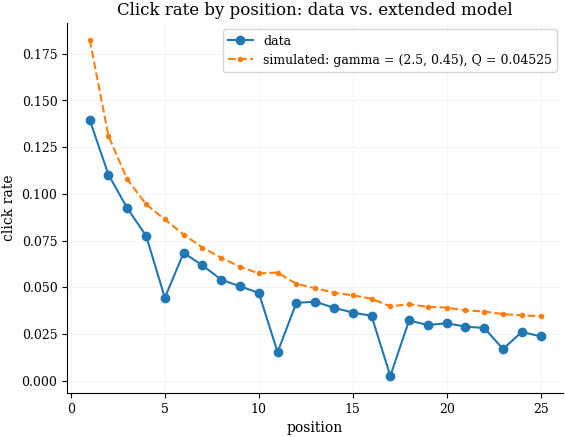

In [ ]:
### Click rate by position: data vs. extended model at the grid minimum
click_file = RES / 'click_fit.csv'
if RUN_GRID or not click_file.exists():
    click_sim = sim_click_rate(theta_hat, X_ext, gamma_0_hat, gamma_pos_hat, eps_draws)  # R simulations: about a minute
    click_sim.to_csv(click_file)
else:
    click_sim = pd.read_csv(click_file, index_col=0).squeeze('columns')

a_data.groupby(level='j').mean().loc[1:25].plot(marker='o', label='data')
click_sim.loc[1:25].plot(
    ls='--', marker='.',
    label=f"simulated: gamma = ({gamma_0_hat:g}, {gamma_pos_hat:g}), Q = {best['Q']:.5f}")
plt.xlabel('position'); plt.ylabel('click rate')
plt.title('Click rate by position: data vs. extended model')
plt.legend(); plt.grid(alpha=0.3)
#plt.savefig(RES / 'click_fit.pdf', bbox_inches='tight')
plt.show()

In [26]:
print('Extended model estimates (grid minimum):')
display(pd.DataFrame({'theta (baseline)': theta_hat, 'gamma (search cost)': gamma_hat, 'beta (taste)': beta_hat}).round(3))

Extended model estimates (grid minimum):


,theta (baseline),gamma (search cost),beta (taste)
log_price,-0.754,0.00,-0.754
stars,0.233,0.00,0.233
zero_stars,0.259,0.00,0.259
position_log,-0.656,0.45,-0.206
review,0.234,0.00,0.234
zero_review,-0.090,0.00,-0.090
prop_brand_bool,0.428,0.00,0.428
prop_location_score1,-0.030,0.00,-0.030
promotion_flag,0.225,0.00,0.225
constant,-1.873,2.50,0.627


In [27]:
print('Price equivalent, % price increase (extended model):')
display(table_ext)
print(f"alpha (extended) = {alpha_ext:.3f}, alpha (simple) = {-theta_hat['log_price']:.3f}")
print(f"markup: mean = {hotels_ext['markup'].mean():.2f} USD")
print(f"Lerner index (p - c)/p: mean = {hotels_ext['lerner'].mean():.3f}")


Price equivalent, % price increase (extended model):


,Simple logit,Taste,Search cost
Move,,,
2 → 1,82.7,20.8,51.2
3 → 2,42.3,11.7,27.4
4 → 3,28.4,8.2,18.7
5 → 4,21.4,6.3,14.2
6 → 5,17.2,5.1,11.5
7 → 6,14.3,4.3,9.6
8 → 7,12.3,3.7,8.3
9 → 8,10.8,3.3,7.3
10 → 9,9.6,2.9,6.5


alpha (extended) = 0.754, alpha (simple) = 0.754
markup: mean = 323.52 USD
Lerner index (p - c)/p: mean = 1.333


## Ranking

Three rankings of the same Expedia (default-ranking) sessions. Every hotel keeps its attributes; only its position changes:
* **Expedia**: the positions Expedia showed.
* **Random**: the hotels of each session in a random order.
* **Best first**: sorted by $\mathbf{x}_{ij}'\hat\theta - \hat\theta_{pos}\log(\text{Rank}_{ij})$, the part of $\delta_{ij} - \mu_{ij}$ the hotel brings with it wherever it is shown.

Bookings and consumer surplus follow from the logit in $\delta_{ij} - \mu_{ij} = \mathbf{x}_{ij}'\hat\theta$. Searches are simulated at $(\hat\beta, \hat\gamma)$, with the same draws for all three rankings.


In [28]:
### Setup: the Expedia sessions, and the three rankings
df_def = df[df['random_bool'] == 0]
miss_review_def = df_def['review'].isna().groupby(level='i').transform('any')
df_def = df_def[~miss_review_def] # drop the sessions with a missing review, as for the random sample
X_def = df_def[xvars].astype(float)
assert not X_def.isna().any().any(), 'X has missing values'
price_def = df_def.loc[X_def.index, 'price_usd']        # observed prices, aligned with X_def (held fixed)

def rerank(X_, score):
    '''X_ with the session's own slots reassigned by the order of score (best score -> lowest slot).
    Keeps the gaps (opaque-offer slots), so only the order changes. Outside rows keep 0.'''
    I_in = X_.index.get_level_values('j') > 0
    X_new = X_.copy()
    order = score[I_in].groupby(level='i').rank(ascending=False, method='first').astype(int)   # 1 = best
    slots = pd.Series(X_.index.get_level_values('j')[I_in].astype(float), index=order.index)
    sorted_slots = slots.groupby(level='i').transform(lambda s: np.sort(s.values))           # k-th smallest slot
    new_slot = order.groupby(level='i').transform(lambda o: sorted_slots.loc[o.index].values[o.values - 1])
    X_new.loc[I_in, 'position_log'] = np.log(new_slot.values)
    return X_new

def logsum(v):
    '''Consumer surplus by session, up to a constant. v is delta_ij - mu_ij, outside rows included.'''
    return np.log(np.exp(v).groupby(level='i').sum())

def booked(v):
    '''The share of sessions that book a hotel. The outside row of v supplies the "1 +".'''
    return 1 - (1 / np.exp(v).groupby(level='i').sum()).mean()

def booked_price(v, price):
    '''Expected mean price of the booked hotel: each hotel weighted by its booking probability s_ij.'''
    ev = np.exp(v - v.groupby(level='i').transform('max'))
    s = ev / ev.groupby(level='i').transform('sum')     # logit probabilities, outside option included
    I_in = v.index.get_level_values('j') > 0
    return (s[I_in] * price[I_in]).sum() / s[I_in].sum()

score_random = pd.Series(np.random.default_rng(11).uniform(size=len(X_def)), X_def.index)
score_best = X_def @ theta_hat - theta_hat['position_log'] * X_def['position_log'] # x_ij' theta_hat without the position term

X_rank = {'Expedia': X_def,
          'Random': rerank(X_def, score_random),
          'Best first': rerank(X_def, score_best)}

In [29]:
### Compare the three rankings
eps_def = pd.Series(np.random.default_rng(12).gumbel(size=len(X_def)), X_def.index) # the same draws for all three rankings
v_expedia = X_def @ theta_hat

rows = {}
for name, X_r in tqdm(X_rank.items(), desc='rankings'):
    v_r = X_r @ theta_hat
    n_search = simulated_searches(X_r @ beta_hat, X_r @ gamma_hat, eps_def, seed=3).groupby(level='i').sum()
    p = booked_price(v_r, price_def)
    p = p[0] if isinstance(p, tuple) else p                      # mean only
    rows[name] = {
        ('Among searchers', 'Booking rate'):                    booked(v_r),
        ('Among searchers', 'Consumer surplus vs Expedia'):     (logsum(v_r) - logsum(v_expedia)).mean(),
        ('Among searchers', 'Mean price of booked hotel ($)'):  p,
        ('Among searchers', 'Clicks per searcher'):             n_search[n_search > 0].mean(),
        ('Model prediction, not in data', 'Share who click nothing'): (n_search == 0).mean(),
    }
tab_rank = pd.DataFrame(rows).T
tab_rank.columns = pd.MultiIndex.from_tuples(tab_rank.columns)
display(tab_rank.round(3))

rankings: 100%|██████████| 3/3 [00:07<00:00,  2.35s/it]


Among searchers                              \
              Booking rate Consumer surplus vs Expedia   
Expedia              0.152                       0.000   
Random               0.146                      -0.007   
Best first           0.170                       0.023   

                                                               \
           Mean price of booked hotel ($) Clicks per searcher   
Expedia                           131.052               1.446   
Random                            130.179               1.446   
Best first                        118.260               1.452   

           Model prediction, not in data  
                 Share who click nothing  
Expedia                            0.446  
Random                             0.447  
Best first                         0.438

# Robustness check
## run model with $\alpha = 2$

In [30]:
### Functions for evaluating the rankings (used by the alpha sweep and the log vs linear comparison)
def rerank_v(X_, score, pos_var):
    '''rerank for any position variable: the session's own slots reassigned by score. Keeps the gaps.'''
    I_in = X_.index.get_level_values('j') > 0
    X_new = X_.copy()
    order = score[I_in].groupby(level='i').rank(ascending=False, method='first').astype(int)
    slots = pd.Series(X_.index.get_level_values('j')[I_in].astype(float), index=order.index)
    sorted_slots = slots.groupby(level='i').transform(lambda s: np.sort(s.values))
    new_slot = order.groupby(level='i').transform(lambda o: sorted_slots.loc[o.index].values[o.values - 1])
    X_new.loc[I_in, pos_var] = np.log(new_slot.values) if pos_var == 'position_log' else new_slot.values
    return X_new

def evaluate_rankings(theta, beta, gamma, xv, pos_var):
    X_d = df_def[xv].astype(float)
    score_random = pd.Series(np.random.default_rng(11).uniform(size=len(X_d)), X_d.index)   # as in the main table
    score_best = X_d @ theta - theta[pos_var] * X_d[pos_var]                                 # without the position term
    X_r_all = {'Expedia': X_d,
               'Random': rerank_v(X_d, score_random, pos_var),
               'Best first': rerank_v(X_d, score_best, pos_var)}
    eps = pd.Series(np.random.default_rng(12).gumbel(size=len(X_d)), X_d.index)             # as in the main table
    v_exp = X_d @ theta

    rows = {}
    for name, X_r in X_r_all.items():
        v = X_r @ theta
        n_search = simulated_searches(X_r @ beta, X_r @ gamma, eps, seed=3).groupby(level='i').sum()
        p = booked_price(v, price_def)
        p = p[0] if isinstance(p, tuple) else p                      # mean only
        rows[name] = {
            ('Among searchers', 'Booking rate'):                    booked(v),
            ('Among searchers', 'Consumer surplus vs Expedia'):     (logsum(v) - logsum(v_exp)).mean(),
            ('Among searchers', 'Mean price of booked hotel ($)'):  p,
            ('Among searchers', 'Clicks per searcher'):             n_search[n_search > 0].mean(),
            ('Model prediction, not in data', 'Share who click nothing'): (n_search == 0).mean(),
        }
    out = pd.DataFrame(rows).T
    out.columns = pd.MultiIndex.from_tuples(out.columns)
    return out

alpha: 100%|██████████| 6/6 [04:11<00:00, 41.92s/it]


Booking rate                   Consumer surplus vs Expedia         \
           Expedia Random Best first                     Expedia Random   
alpha                                                                     
0.754        0.152  0.146      0.170                         0.0 -0.007   
1.000        0.153  0.147      0.175                         0.0 -0.007   
1.500        0.153  0.148      0.187                         0.0 -0.006   
2.000        0.152  0.148      0.198                         0.0 -0.005   
2.500        0.150  0.148      0.207                         0.0 -0.004   
3.000        0.147  0.146      0.214                         0.0 -0.003   

                 Mean price of booked hotel ($)                      \
      Best first                        Expedia   Random Best first   
alpha                                                                 
0.754      0.023                        131.052  130.179    118.260   
1.000      0.028                        121.870  120.686    105.857   
1.500      0.044                        106.213  104.781     88.620   
2.000      0.063                         93.361   91.959     77.067   
2.500      0.083                         82.739   81.487     68.764   
3.000      0.102                         73.996   72.940     62.593   

      Clicks per searcher                   Share who click nothing         \
                  Expedia Random Best first                 Expedia Random   
alpha                                                                        
0.754               1.446  1.446      1.452                   0.446  0.447   
1.000               1.446  1.447      1.454                   0.445  0.447   
1.500               1.446  1.446      1.456                   0.444  0.445   
2.000               1.446  1.446      1.458                   0.443  0.444   
2.500               1.446  1.445      1.461                   0.442  0.441   
3.000               1.446  1.447      1.463                   0.440  0.440   

                  
      Best first  
alpha             
0.754      0.438  
1.000      0.435  
1.500      0.431  
2.000      0.424  
2.500      0.418  
3.000      0.414

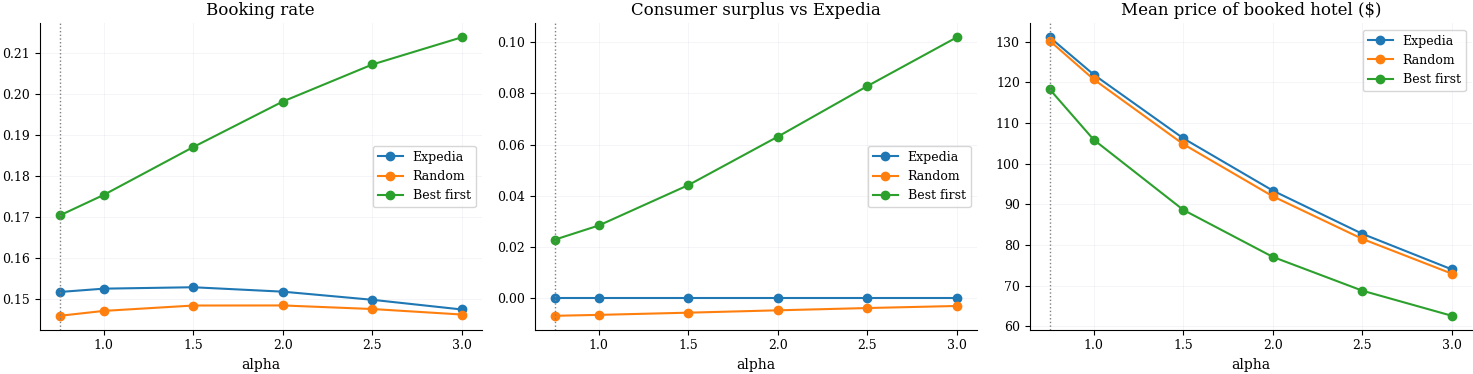

In [ ]:
### Sensitivity: vary alpha only, all other coefficients fixed
### (constant set so the predicted booking rate in the estimation sample equals the observed one, as ML would)
alphas = [-theta_hat['log_price'], 1.0, 1.5, 2.0, 2.5, 3.0]
observed_rate = 1 - df_rand.loc[df_rand.index.get_level_values('j') == 0, 'booking_bool'].mean()   # observed booking rate, random sample

def theta_with_alpha(a):
    '''theta_hat with the log-price coefficient set to -a and the constant shifted so that
    the predicted booking rate in the estimation sample equals the observed one.'''
    th = theta_hat.copy()
    th['log_price'] = -a
    def gap(c):
        th_c = th.copy(); th_c['constant'] = c
        return booked(X_rand @ th_c) - observed_rate
    th['constant'] = brentq(gap, theta_hat['constant'] - 40, theta_hat['constant'] + 40)
    return th

results = {}
for a in tqdm(alphas, desc='alpha'):
    th = theta_with_alpha(a)
    be = th + gamma_hat                             # gamma (search costs) as estimated
    cf_a = evaluate_rankings(th, be, gamma_hat, xvars, 'position_log')
    cf_a.columns = cf_a.columns.get_level_values(-1)   # drop the column groups
    results[round(a, 3)] = {(c, r): cf_a.loc[r, c] for c in cf_a.columns for r in cf_a.index}

sens = pd.DataFrame(results).T
sens.index.name = 'alpha'
sens.columns = pd.MultiIndex.from_tuples(sens.columns)
display(sens.round(3))
sens.round(4).to_csv(RES / 'sensitivity_alpha.csv')

# plot each outcome against alpha, one line per ranking
outcomes = ['Booking rate', 'Consumer surplus vs Expedia', 'Mean price of booked hotel ($)']
fig, axs = plt.subplots(1, len(outcomes), figsize=(15, 4))
for ax, c in zip(axs, outcomes):
    for r in ['Expedia', 'Random', 'Best first']:
        sens[(c, r)].plot(ax=ax, marker='o', label=r)
    ax.axvline(-theta_hat['log_price'], color='grey', ls=':', lw=1)   # the estimated alpha
    ax.set_title(c); ax.set_xlabel('alpha'); ax.legend(); ax.grid(alpha=0.3)
#plt.tight_layout(); plt.savefig(RES / 'sensitivity_alpha.pdf', bbox_inches='tight'); plt.show()

In [32]:
### Price equivalent and markup: estimated alpha vs alpha = 2 (other coefficients fixed, constant shifted)
th_est, th_2 = theta_hat, theta_with_alpha(2.0)

def markup_summary(th):
    d = df_rand.copy()
    d['s'] = predict_shares(th, d)
    h = d[d.index.get_level_values('j') > 0]
    a = -th['log_price']
    markup = h['price_usd'] / (a * (1 - h['s']))
    return {'Lerner index (mean)': (markup / h['price_usd']).mean(),
            'Markup, median ($)': markup.median(),
            'Marginal cost, median ($)': (h['price_usd'] - markup).median()}

def pe_summary(th):
    return {f'Price equivalent {p}→{p-1} (%)': 100 * (np.exp(price_change(th, p)) - 1) for p in [2, 5, 10]}

pe_mk = pd.DataFrame({f'Estimated (alpha = {-th_est["log_price"]:.2f})': {**pe_summary(th_est), **markup_summary(th_est)},
                      'alpha = 2': {**pe_summary(th_2), **markup_summary(th_2)}})
display(pe_mk.round(2))
pe_mk.round(4).to_csv(RES / 'pe_markup_alpha_est_vs_2.csv')

,Estimated (alpha = 0.75),alpha = 2
Price equivalent 2→1 (%),82.72,25.53
Price equivalent 5→4 (%),21.42,7.59
Price equivalent 10→9 (%),9.60,3.52
Lerner index (mean),1.33,1.05
"Markup, median ($)",171.31,64.57
"Marginal cost, median ($)",-42.58,63.92


In [33]:
### Counterfactual rankings: estimated alpha vs alpha = 2 (from the sweep)
a_est = -theta_hat['log_price']
pick = lambda a: sens.index[np.argmin(np.abs(sens.index.astype(float) - a))]   # the sweep row closest to a

def as_table(a):
    row = sens.loc[pick(a)]
    return row.unstack(level=0)                       # rows: rankings, columns: outcomes

comp = pd.concat({f'Estimated (alpha = {a_est:.2f})': as_table(a_est),
                  'alpha = 2':                        as_table(2.0)})
comp.index.names = ['Model', 'Ranking']
order = ['Expedia', 'Random', 'Best first']
comp = comp.reindex(pd.MultiIndex.from_product([comp.index.levels[0], order], names=comp.index.names))
cols = ['Booking rate', 'Consumer surplus vs Expedia', 'Mean price of booked hotel ($)',
        'Clicks per searcher', 'Share who click nothing']
comp = comp[[c for c in cols if c in comp.columns]]
display(comp.round(3))
comp.round(4).to_csv(RES / 'rankings_alpha_est_vs_2.csv')

Booking rate  \
Model                    Ranking                    
Estimated (alpha = 0.75) Expedia            0.152   
                         Random             0.146   
                         Best first         0.170   
alpha = 2                Expedia            0.152   
                         Random             0.148   
                         Best first         0.198   

                                     Consumer surplus vs Expedia  \
Model                    Ranking                                   
Estimated (alpha = 0.75) Expedia                           0.000   
                         Random                           -0.007   
                         Best first                        0.023   
alpha = 2                Expedia                           0.000   
                         Random                           -0.005   
                         Best first                        0.063   

                                     Mean price of booked hotel ($)  \
Model                    Ranking                                      
Estimated (alpha = 0.75) Expedia                            131.052   
                         Random                             130.179   
                         Best first                         118.260   
alpha = 2                Expedia                             93.361   
                         Random                              91.959   
                         Best first                          77.067   

                                     Clicks per searcher  \
Model                    Ranking                           
Estimated (alpha = 0.75) Expedia                   1.446   
                         Random                    1.446   
                         Best first                1.452   
alpha = 2                Expedia                   1.446   
                         Random                    1.446   
                         Best first                1.458   

                                     Share who click nothing  
Model                    Ranking                              
Estimated (alpha = 0.75) Expedia                       0.446  
                         Random                        0.447  
                         Best first                    0.438  
alpha = 2                Expedia                       0.443  
                         Random                        0.444  
                         Best first                    0.424

## Results of counterfactual (with robustness check)

In [34]:
# ---------- counterfactual rankings, estimated alpha and alpha = 2 ----------
n_sess_def = X_def.index.get_level_values('i').nunique()
cols4 = ['Booking rate', 'Consumer surplus vs Expedia', 'Mean price of booked hotel ($)',
         'Clicks per searcher', 'Share who click nothing']
fmt4 = {'Booking rate': f3,
        'Consumer surplus vs Expedia': f3,
        'Mean price of booked hotel ($)': f1,
        'Clicks per searcher': lambda x: f'{x:.2f}',
        'Share who click nothing': f3}

panels = [(comp.index.levels[0][0], f'Panel A: estimated price coefficient ($\\alpha = {a_est:.2f}$)'),
          ('alpha = 2',             r'Panel B: sensitivity, $\alpha = 2$')]

t4 = [r'\begin{table}[htbp]', r'\centering', r'\caption{Counterfactual rankings}', r'\label{tab:rankings}',
      r'\small', r'\setlength{\tabcolsep}{5pt}',
      r'\begin{tabular}{lccccc}', r'\toprule',
      r' & \multicolumn{4}{c}{Among searchers} & \\', r'\cmidrule(lr){2-5}',
      r' & Booking & CS vs & Price & Clicks per & Share \\',
      r'Ranking & rate & Expedia & booked (\$) & searcher & no click$^{\dagger}$ \\',
      r'\midrule']

for k, (model_label, title) in enumerate(panels):
    if k > 0:
        t4.append(r'\midrule')
    t4.append(f'\\multicolumn{{6}}{{l}}{{\\textit{{{title}}}}} \\\\')
    for rk in ['Expedia', 'Random', 'Best first']:
        r_ = comp.loc[(model_label, rk)]
        t4.append(f'{rk} & ' + ' & '.join(fmt4[c](r_[c]) for c in cols4) + r' \\')

t4 += [r'\bottomrule', r'\end{tabular}', '',
       r'\begin{minipage}{0.85\linewidth}\vspace{4pt}\footnotesize \textit{Note:} '
       + f'{n_sess_def:,} Expedia (default-ranking) sessions; sessions with a missing review score dropped. '
       + r"Every hotel keeps its attributes and observed price; only its position changes, within the session's own slots (opaque-offer slots kept). "
       + r"Expedia: the positions shown. Random: hotels in random order. Best first: sorted by $\mathbf{x}_{ij}'\hat\theta$ without the position term. "
       + r"Booking rate, consumer surplus (mean change in the logsum, in utility units) and the booking-weighted mean price follow from the logit in $\mathbf{x}_{ij}'\hat\theta$, "
       + r'and refer to consumers who search. Clicks are simulated at $(\hat\beta, \hat\gamma)$ with the same draws for all rankings. '
       + r'Panel B sets $\alpha = 2$, keeps all other coefficients, and sets the constant so the predicted booking rate in the estimation sample equals the observed one; '
       + r'its best-first ranking is built with $\alpha = 2$. Consumer surplus is in utility units within each panel. '
       + r'$^{\dagger}$Share of simulated consumers who click nothing: a model prediction for a margin not observed in the data, '
       + r'which contain only sessions with at least one click.'
       + r'\end{minipage}',
       r'\end{table}']

write_tex('tab_rankings.tex', t4)

written: res/tab_rankings.tex


# NOT USED IN THE REPORT: Robustness check
## run model with position entering linearly

In [ ]:
### Linear position: estimate theta, then gamma on a grid. Saved to res/ like the main model.
RUN_GRID_LIN = True     # False: load from res/estimates_lin.csv and res/grid_Q_lin.csv

xvars_lin = [('position_num' if v == 'position_log' else v) for v in xvars]
X_rand_lin = df_rand[xvars_lin].astype(float)

if RUN_GRID_LIN:
    res_lin = minimize(loglike, np.zeros(len(xvars_lin)), args=(X_rand_lin, I_chosen_rand), method='BFGS')
    print(res_lin.message)
    theta_lin = pd.Series(res_lin.x, xvars_lin)

    # gamma_pos as shares of -theta_pos (0 = all taste, 1 = all search cost); same gamma_0 grid as the log model
    gp_grid_lin = list(np.round(-theta_lin['position_num'] * np.array([0, 0.25, 0.5, 0.75, 1.0, 1.25]), 4))
    tab_grid_lin = grid_search(X_rand_lin, theta_lin, a_data, eps_draws, xvars_lin, 'position_num', g0_grid, gp_grid_lin)
    tab_grid_lin.to_csv(RES / 'grid_Q_lin.csv', index=False)
else:
    theta_lin = pd.read_csv(RES / 'estimates_lin.csv', index_col=0)['theta']
    assert list(theta_lin.index) == xvars_lin, 'xvars have changed: set RUN_GRID_LIN = True'
    tab_grid_lin = pd.read_csv(RES / 'grid_Q_lin.csv')

best_lin = tab_grid_lin.loc[tab_grid_lin['Q'].idxmin()]
gamma_hat_lin = gamma_from(best_lin['gamma_0'], best_lin['gamma_pos'], xvars_lin, 'position_num')
beta_hat_lin = theta_lin + gamma_hat_lin
# pd.DataFrame({'theta': theta_lin, 'gamma': gamma_hat_lin, 'beta': beta_hat_lin}).to_csv(RES / 'estimates_lin.csv')

display(tab_grid_lin.pivot(index='gamma_0', columns='gamma_pos', values='Q').round(5))
print(f"minimum: gamma_0 = {best_lin['gamma_0']}, gamma_pos = {best_lin['gamma_pos']}, Q = {best_lin['Q']:.5f}")

Optimization terminated successfully.


grid position_num, R = 50: 100%|██████████| 42/42 [30:39<00:00, 43.80s/it]


gamma_pos,0.0000,0.0195,0.0390,0.0585,0.0779,0.0974
gamma_0,,,,,,
1.75,0.06464,0.05389,0.04963,0.04785,0.04707,0.04678
2.00,0.05580,0.04967,0.04734,0.04642,0.04608,0.04602
2.25,0.05092,0.04744,0.04614,0.04570,0.04561,0.04567
2.50,0.04827,0.04627,0.04557,0.04540,0.04544,0.04558
2.75,0.04687,0.04573,0.04538,0.04535,0.04546,0.04564
3.00,0.04616,0.04552,0.04537,0.04545,0.04563,0.04588
3.25,0.04589,0.04555,0.04554,0.04569,0.04592,0.04619


minimum: gamma_0 = 2.75, gamma_pos = 0.0585, Q = 0.04535


Log position              Linear position              
                            theta gamma   beta           theta  gamma   beta
log_price                  -0.754  0.00 -0.754          -0.762  0.000 -0.762
stars                       0.233  0.00  0.233           0.237  0.000  0.237
zero_stars                  0.259  0.00  0.259           0.266  0.000  0.266
position_log               -0.656  0.45 -0.206             NaN    NaN    NaN
review                      0.234  0.00  0.234           0.230  0.000  0.230
zero_review                -0.090  0.00 -0.090          -0.110  0.000 -0.110
prop_brand_bool             0.428  0.00  0.428           0.432  0.000  0.432
prop_location_score1       -0.030  0.00 -0.030          -0.031  0.000 -0.031
promotion_flag              0.225  0.00  0.225           0.233  0.000  0.233
constant                   -1.873  2.50  0.627          -2.246  2.750  0.504
position_num                  NaN   NaN    NaN          -0.078  0.058 -0.019

,Log position,Linear position
gamma_0,2.5000,2.7500
gamma_pos,0.4500,0.0585
Q at minimum,0.0453,0.0453
Search-cost share of position,0.6859,0.7505
Purchase log-likelihood (mean),-0.7711,-0.7722


Log       Linear      
        Total Taste  Total Taste
2 → 1    82.7  20.8   10.8   2.6
3 → 2    42.3  11.7   10.8   2.6
5 → 4    21.4   6.3   10.8   2.6
10 → 9    9.6   2.9   10.8   2.6
20 → 19   4.6   1.4   10.8   2.6

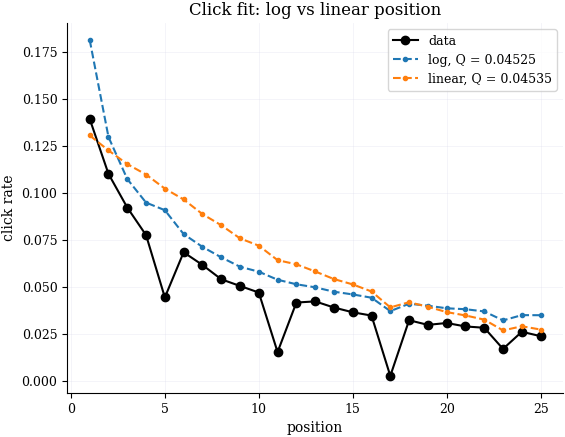

In [ ]:
### Linear vs log position: parameters, fit and price equivalents
params = pd.concat({
    ('Log position', 'theta'): theta_hat,  ('Log position', 'gamma'): gamma_hat,  ('Log position', 'beta'): beta_hat,
    ('Linear position', 'theta'): theta_lin, ('Linear position', 'gamma'): gamma_hat_lin, ('Linear position', 'beta'): beta_hat_lin,
}, axis=1)
display(params.round(3))

# fit and identification of the split
pos_share = lambda g, th, pv: g[pv] / -th[pv]          # share of the position effect that is search cost
summary = pd.DataFrame({
    'Log position':    {'gamma_0': best['gamma_0'], 'gamma_pos': best['gamma_pos'], 'Q at minimum': best['Q'],
                        'Search-cost share of position': pos_share(gamma_hat, theta_hat, 'position_log'),
                        'Purchase log-likelihood (mean)': -res_baseline.fun if RUN_GRID else np.nan},
    'Linear position': {'gamma_0': best_lin['gamma_0'], 'gamma_pos': best_lin['gamma_pos'], 'Q at minimum': best_lin['Q'],
                        'Search-cost share of position': pos_share(gamma_hat_lin, theta_lin, 'position_num'),
                        'Purchase log-likelihood (mean)': -res_lin.fun if RUN_GRID_LIN else np.nan}})
display(summary.round(4))

# price equivalent of moving one position up (% price increase): total, taste, search cost
pe = lambda th, pos, pv: 100 * (np.exp(price_change(th, pos, pv)) - 1)
moves = [2, 3, 5, 10, 20]
pe_tab = pd.DataFrame({
    ('Log', 'Total'):  [pe(theta_hat, p, 'position_log') for p in moves],
    ('Log', 'Taste'):  [pe(beta_hat, p, 'position_log') for p in moves],
    ('Linear', 'Total'): [pe(theta_lin, p, 'position_num') for p in moves],
    ('Linear', 'Taste'): [pe(beta_hat_lin, p, 'position_num') for p in moves],
}, index=[f'{p} → {p-1}' for p in moves])
display(pe_tab.round(1))

# click fit: data vs both models at their grid minima
def sim_click_rate_v(theta_, X_, g0, gp, xv, pos_var, eps_draws_):
    gamma = gamma_from(g0, gp, xv, pos_var)
    beta = theta_ + gamma
    a_sim = pd.concat([simulated_searches(X_ @ beta, X_ @ gamma, eps, seed=3 + r)
                       for r, eps in enumerate(eps_draws_)], axis=1).astype(float)
    any_search = a_sim.groupby(level='i').transform('max')
    return ((a_sim * any_search).sum(axis=1) / any_search.sum(axis=1)).groupby(level='j').mean()

R_plot = 20   # fewer draws for the plot; use eps_draws for all 50
a_data.groupby(level='j').mean().loc[1:25].plot(marker='o', color='black', label='data')
sim_click_rate_v(theta_hat, X_ext, best['gamma_0'], best['gamma_pos'], xvars, 'position_log',
                 eps_draws[:R_plot]).loc[1:25].plot(ls='--', marker='.', label=f"log, Q = {best['Q']:.5f}")
sim_click_rate_v(theta_lin, X_rand_lin, best_lin['gamma_0'], best_lin['gamma_pos'], xvars_lin, 'position_num',
                 eps_draws[:R_plot]).loc[1:25].plot(ls='--', marker='.', label=f"linear, Q = {best_lin['Q']:.5f}")
plt.xlabel('position'); plt.ylabel('click rate'); plt.title('Click fit: log vs linear position')
plt.legend(); plt.grid(alpha=0.3)
#plt.savefig(RES / 'click_fit_log_vs_lin.pdf', bbox_inches='tight'); plt.show()

params.round(4).to_csv(RES / 'params_log_vs_lin.csv')

In [37]:
cf = pd.concat({'Log position': evaluate_rankings(theta_hat, beta_hat, gamma_hat, xvars, 'position_log'),
                'Linear position': evaluate_rankings(theta_lin, beta_hat_lin, gamma_hat_lin, xvars_lin, 'position_num')})
cf.index.names = ['Model', 'Ranking']
display(cf.round(3))

cf.round(4).to_csv(RES / 'rankings_log_vs_lin.csv')

Among searchers                              \
                              Booking rate Consumer surplus vs Expedia   
Model           Ranking                                                  
Log position    Expedia              0.152                       0.000   
                Random               0.146                      -0.007   
                Best first           0.170                       0.023   
Linear position Expedia              0.151                       0.000   
                Random               0.146                      -0.006   
                Best first           0.169                       0.022   

                                                                               \
                           Mean price of booked hotel ($) Clicks per searcher   
Model           Ranking                                                         
Log position    Expedia                           131.052               1.446   
                Random                            130.179               1.446   
                Best first                        118.260               1.452   
Linear position Expedia                           131.068               1.424   
                Random                            129.942               1.429   
                Best first                        119.310               1.436   

                           Model prediction, not in data  
                                 Share who click nothing  
Model           Ranking                                   
Log position    Expedia                            0.446  
                Random                             0.447  
                Best first                         0.438  
Linear position Expedia                            0.453  
                Random                             0.455  
                Best first                         0.447